# Prueba de `get_stations`

Ejecuta localmente la lambda `get_stations.py`, muestra cómo quedan distribuidas las estaciones elegidas y comprueba,
con `get_observations.py` sin modificar, cuántas devuelven datos útiles. Para comparar, también se corre
`get_observations` sobre la lista actual (`data/raw/metadata_estaciones.json`) en la misma hora.

Las lambdas corren tal cual, con dos reemplazos para el entorno local:

- **S3 en disco**: `boto3` se reemplaza por un objeto que guarda cada key como archivo en `data/s3_local/`. No se
  escribe nada en el bucket real.
- **HTTP con curl**: el `ssl` de Python en este equipo no valida api.weather.gov (lo mismo que en
  `clasificar_estaciones.py`), así que `_get_json` se reemplaza por una versión con curl que mantiene los reintentos
  y el backoff. En Lambda no hace falta.

La selección consulta la API en vivo y tarda unos 2 minutos. Con `EJECUTAR_SELECCION = False` se reusa la última
selección guardada en `data/s3_local/`.

In [1]:
import io
import json
import subprocess
import sys
import time
import types
from contextlib import redirect_stdout
from datetime import datetime, timezone
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAIZ = Path.cwd().parent
sys.path.insert(0, str(RAIZ / 'notebooks'))  # utils.py: paleta y estilo compartidos
sys.path.insert(0, str(RAIZ / 'ETL'))

from utils import AZUL, NARANJA, GRIS_TEXTO, aplicar_estilo

aplicar_estilo()

S3_LOCAL = RAIZ / 'data/s3_local'
EJECUTAR_SELECCION = True
N_ESTACIONES = 500

## 1. Entorno local: S3 en disco y HTTP con curl

In [2]:
class S3Local:
    # Imita put_object y get_object de boto3: cada key es un archivo dentro de S3_LOCAL.
    def put_object(self, Bucket, Key, Body, ContentType=None):
        ruta = S3_LOCAL / Key
        ruta.parent.mkdir(parents=True, exist_ok=True)
        ruta.write_bytes(Body)

    def get_object(self, Bucket, Key):
        return {'Body': io.BytesIO((S3_LOCAL / Key).read_bytes())}


def leer_json(key):
    return json.loads((S3_LOCAL / key).read_text(encoding='utf-8'))


sys.modules['boto3'] = types.SimpleNamespace(client=lambda servicio: S3Local())

import get_observations
import get_stations

llamadas_http = 0


def _get_json_curl(url, intentos=3):
    # Mismo contrato que _get_json de las lambdas: reintenta 429/5xx con backoff y lanza RuntimeError.
    global llamadas_http
    ultimo_error = None
    for intento in range(intentos):
        llamadas_http += 1
        res = subprocess.run(
            ['curl', '-s', '-L', '-m', str(get_stations.HTTP_TIMEOUT), '-w', '\n%{http_code}',
             '-H', f'User-Agent: {get_stations.USER_AGENT}', url],
            capture_output=True,
        )
        cuerpo, _, codigo = res.stdout.decode('utf-8').rpartition('\n')
        if res.returncode == 0 and codigo == '200':
            return json.loads(cuerpo)
        ultimo_error = f'HTTP {codigo}' if res.returncode == 0 else f'curl exit {res.returncode}'
        if res.returncode == 0 and int(codigo) not in (429, 500, 502, 503, 504):
            break
        time.sleep(2 ** intento)
    raise RuntimeError(ultimo_error)


for modulo in (get_stations, get_observations):
    modulo._get_json = _get_json_curl

## 2. Selección de estaciones

`lambda_handler` recibe un contexto con 15 minutos disponibles, igual que con el timeout recomendado en Lambda.

In [3]:
class Contexto:
    def get_remaining_time_in_millis(self):
        return 15 * 60 * 1000


if EJECUTAR_SELECCION:
    llamadas_http, t0 = 0, time.time()
    log = io.StringIO()
    with redirect_stdout(log):
        get_stations.lambda_handler({'n_estaciones': N_ESTACIONES}, Contexto())
    print(log.getvalue().splitlines()[0])
    print(f'Duración: {time.time() - t0:.0f} s, {llamadas_http:,} llamadas HTTP')

manifiesto = leer_json(get_stations.MANIFIESTO_KEY)
seleccion = pd.DataFrame(leer_json(get_stations.METADATA_KEY))
grids = pd.DataFrame(leer_json(get_stations.GRIDS_KEY))

print(f"\nSelección del {manifiesto['fecha_utc'][:16]} UTC"
      f"{' (INCOMPLETA: se alcanzó el límite de tiempo)' if manifiesto['incompleta'] else ''}")
print(f"  Estaciones listadas por la API:  {manifiesto['estaciones_listadas']:,}")
for motivo, n in manifiesto['descartes_prefiltro'].items():
    print(f'    descartadas sin consultar ({motivo}): {n:,}')
print(f"  Verificadas en la API:           {manifiesto['verificadas']:,}")
for motivo, n in manifiesto['descartes_verificacion'].items():
    print(f'    descartadas ({motivo}): {n}')
print(f"  Seleccionadas:                   {manifiesto['seleccionadas']}"
      f" (metadata: {len(seleccion)}, grids: {len(grids)})")

12635 estaciones en 15 estados; 5017 candidatas tras el prefiltro {'red_excluida': 3622, 'sin_proveedor': 3996}.
Duración: 162 s, 1,331 llamadas HTTP

Selección del 2026-10-15T01:33 UTC
  Estaciones listadas por la API:  12,635
    descartadas sin consultar (red_excluida): 3,622
    descartadas sin consultar (sin_proveedor): 3,996
  Verificadas en la API:           680
    descartadas (variables_incompletas): 73
    descartadas (sin_forecastHourly): 5
    descartadas (sin_observaciones): 4
    descartadas (inactiva): 3
  Seleccionadas:                   500 (metadata: 500, grids: 500)


### Cupos por estado

El cupo es proporcional al área. La columna *actuales útiles* cuenta las estaciones de la lista actual que sí
reportan variables (`cobertura_estaciones.csv`, sin las categorías `sin_meteo` y `sin_registros`).

In [4]:
actual = pd.read_json(RAIZ / 'data/raw/metadata_estaciones.json')
categorias = pd.read_csv(RAIZ / 'data/processed/cobertura_estaciones.csv', usecols=['station_id', 'categoria'])
actual = actual.merge(categorias, left_on='id', right_on='station_id', how='left')
actual_utiles = actual[~actual['categoria'].isin(['sin_meteo', 'sin_registros'])]

por_estado = pd.DataFrame(manifiesto['por_estado']).T
por_estado['area_miles_km2'] = (por_estado['area_km2'] / 1000).round(1)
por_estado['por_10000_km2'] = (por_estado['seleccionadas'] / por_estado['area_km2'] * 1e4).round(2)
por_estado['actuales_utiles'] = actual_utiles['estado'].value_counts().reindex(por_estado.index, fill_value=0)
por_estado = por_estado[['area_miles_km2', 'cupo', 'seleccionadas', 'por_10000_km2', 'actuales_utiles']]
por_estado.sort_values('area_miles_km2', ascending=False)

,area_miles_km2,cupo,seleccionadas,por_10000_km2,actuales_utiles
TX,685.7,114,114,1.66,184
MN,218.5,37,37,1.69,10
KS,213.1,36,36,1.69,5
NE,200.3,33,33,1.65,4
SD,199.7,33,33,1.65,0
ND,183.1,31,31,1.69,1
OK,181.0,30,30,1.66,5
MO,180.5,30,30,1.66,4
MI,150.5,25,25,1.66,13
IL,145.9,24,24,1.64,7


In [5]:
def grupo_red(provider):
    if provider in ('ASOS', 'ASOS-HFM', 'OTHER-MTR', 'NonFedAWOS'):
        return 'Aeropuerto (ASOS/AWOS)'
    if provider == 'RAWS':
        return 'RAWS'
    if provider == 'MesoWest':
        return 'Mesored (MesoWest)'
    return 'Otra (APRS, MARITIME)'


seleccion['grupo_red'] = seleccion['provider'].map(grupo_red)
print(seleccion['grupo_red'].value_counts().to_string())

grupo_red
Aeropuerto (ASOS/AWOS)    401
RAWS                       52
Mesored (MesoWest)         38
Otra (APRS, MARITIME)       9


## 3. Disposición geográfica

A la izquierda, las estaciones actuales que reportan; a la derecha, la selección de `get_stations`, coloreada por tipo
de red.

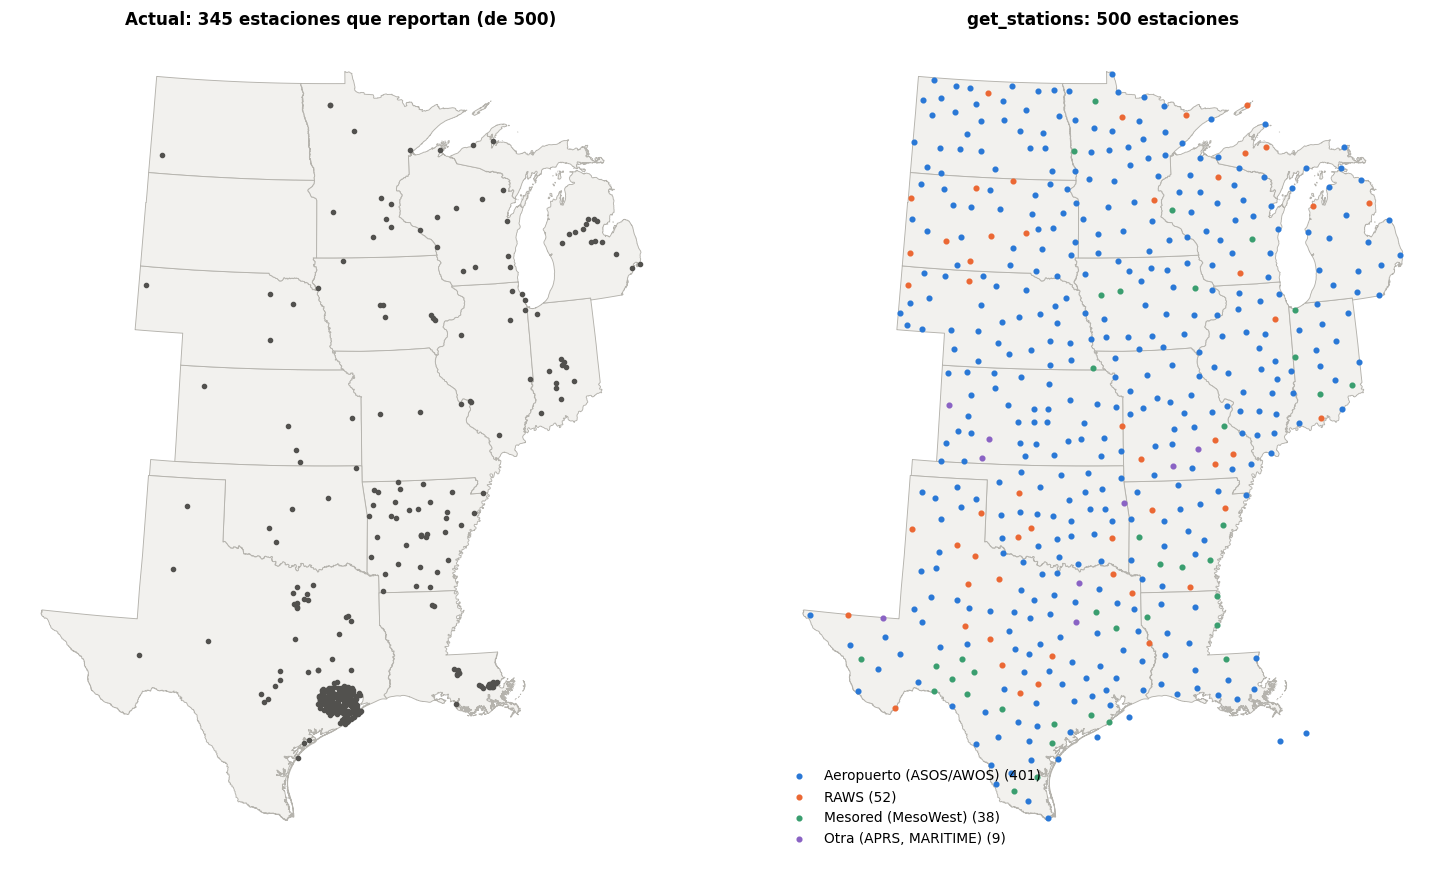

In [6]:
CRS_METRICO = 'EPSG:5070'  # Albers equivalente, igual que analisis_estaciones.ipynb
estados = gpd.read_file(RAIZ / 'data/processed/estados_central.geojson').to_crs(CRS_METRICO)


def a_gdf(df):
    return gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df['longitud'], df['latitud']),
                            crs='EPSG:4326').to_crs(CRS_METRICO)


gdf_actual, gdf_seleccion = a_gdf(actual_utiles), a_gdf(seleccion)

COLORES_RED = {
    'Aeropuerto (ASOS/AWOS)': AZUL, 'RAWS': NARANJA,
    'Mesored (MesoWest)': '#3a9e6f', 'Otra (APRS, MARITIME)': '#8a63c4',
}

fig, (ax_actual, ax_nueva) = plt.subplots(1, 2, figsize=(14, 8))
for ax in (ax_actual, ax_nueva):
    estados.plot(ax=ax, color='#f2f1ee', edgecolor='#b5b3ad', linewidth=0.6)
    ax.set_axis_off()

gdf_actual.plot(ax=ax_actual, markersize=7, color=GRIS_TEXTO)
ax_actual.set_title(f'Actual: {len(gdf_actual)} estaciones que reportan (de {len(actual)})')

for grupo, color in COLORES_RED.items():
    puntos = gdf_seleccion[gdf_seleccion['grupo_red'] == grupo]
    if len(puntos):
        puntos.plot(ax=ax_nueva, markersize=9, color=color, label=f'{grupo} ({len(puntos)})')
ax_nueva.set_title(f'get_stations: {len(gdf_seleccion)} estaciones')
ax_nueva.legend(loc='lower left', frameon=False, fontsize=9)

plt.tight_layout()
plt.show()

### Uniformidad: distancia a la estación vecina más cercana

En una grilla perfecta todas las estaciones estarían a la misma distancia de su vecina (coeficiente de variación,
CV = 0). Los grupos densos, como el de Houston, aparecen como distancias de pocos kilómetros, y los huecos, como
distancias muy largas.

,n,media,p10,mediana,p90,máx.,CV
Actual (reportan),345.0,29.34,3.12,8.81,74.43,459.31,1.74
get_stations,500.0,64.83,51.57,63.09,79.20,134.37,0.18


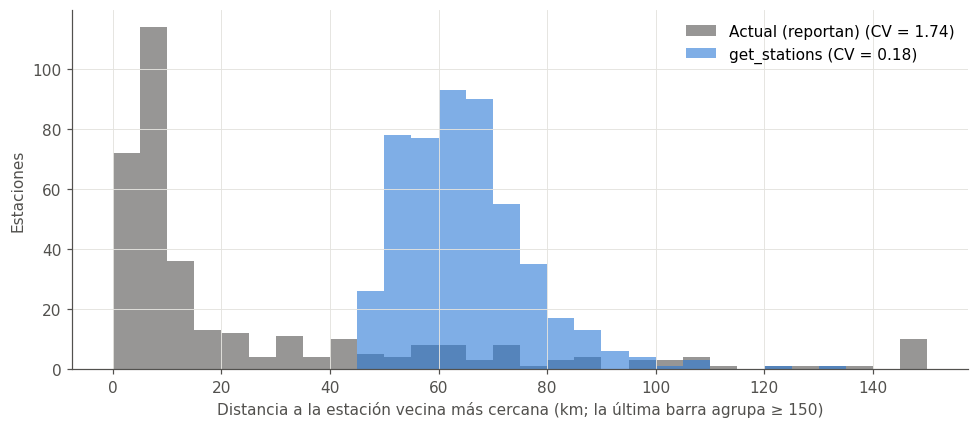

In [7]:
def dist_vecina_km(gdf):
    xy = np.c_[gdf.geometry.x, gdf.geometry.y]
    d = np.sqrt(((xy[:, None] - xy[None]) ** 2).sum(axis=-1))
    np.fill_diagonal(d, np.inf)
    return pd.Series(d.min(axis=1) / 1000, index=gdf.index)


distancias = {'Actual (reportan)': dist_vecina_km(gdf_actual), 'get_stations': dist_vecina_km(gdf_seleccion)}

resumen_dist = pd.DataFrame({
    nombre: {'n': len(d), 'media': d.mean(), 'p10': d.quantile(0.1), 'mediana': d.median(),
             'p90': d.quantile(0.9), 'máx.': d.max(), 'CV': d.std() / d.mean()}
    for nombre, d in distancias.items()
}).T.round(2)
display(resumen_dist)

fig, ax = plt.subplots(figsize=(9, 4))
bins = np.arange(0, 155, 5)
for (nombre, d), color in zip(distancias.items(), [GRIS_TEXTO, AZUL]):
    ax.hist(d.clip(upper=150), bins=bins, color=color, alpha=0.6, label=f'{nombre} (CV = {d.std() / d.mean():.2f})')
ax.set_xlabel('Distancia a la estación vecina más cercana (km; la última barra agrupa ≥ 150)')
ax.set_ylabel('Estaciones')
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## 4. Prueba con `get_observations`

Se corre `get_observations.lambda_handler` dos veces en la misma hora: una con la lista nueva y otra con la actual.
Solo se cambian, desde afuera del módulo, la key de la metadata y el prefijo de salida, para que las dos corridas no
se pisen.

Cada estación se clasifica según lo que devolvió `/observations/latest`:

| Categoría | Criterio |
|---|---|
| útil | trae temperatura, punto de rocío, humedad relativa y velocidad del viento, con una observación de las últimas 2 h |
| parcial | falta alguna de esas cuatro variables |
| sin variables | no trae ninguna de las cuatro (pluviómetros, limnímetros) |
| desactualizada | la última observación tiene más de 2 h: no aporta un dato nuevo para la hora |
| sin respuesta | error HTTP o respuesta sin `properties` (figura en los errores del manifiesto) |

Es una foto de una sola hora. Para una estimación más robusta, se puede repetir esta sección a otras horas.

In [8]:
# La metadata actual también se copia al "bucket" local, en la key por defecto de get_observations.
KEY_METADATA_ACTUAL = 'raw/estaciones/metadata_estaciones.json'
S3Local().put_object('local', KEY_METADATA_ACTUAL, (RAIZ / 'data/raw/metadata_estaciones.json').read_bytes())

hora_corrida = datetime.now(timezone.utc).replace(minute=0, second=0, microsecond=0)


def correr_get_observations(metadata_key, prefijo):
    get_observations.METADATA_KEY = metadata_key
    get_observations.PREFIJO = prefijo
    with redirect_stdout(io.StringIO()):
        get_observations.lambda_handler({'fecha': hora_corrida.isoformat()}, None)
    base = (f'{prefijo}/year={hora_corrida.year}/month={hora_corrida.month:02d}'
            f'/day={hora_corrida.day:02d}/hour={hora_corrida.hour:02d}')
    ruta_obs = S3_LOCAL / base / 'observaciones.jsonl'
    registros = [json.loads(linea) for linea in ruta_obs.read_text(encoding='utf-8').splitlines()] if ruta_obs.exists() else []
    return registros, leer_json(f'{base}/_manifiesto.json')


corridas = {}
for nombre, key, prefijo in [('Actual', KEY_METADATA_ACTUAL, 'prueba/observaciones_actual'),
                             ('get_stations', get_stations.METADATA_KEY, 'prueba/observaciones_get_stations')]:
    t0 = time.time()
    corridas[nombre] = correr_get_observations(key, prefijo)
    m = corridas[nombre][1]
    print(f"{nombre:13s} {m['estaciones_solicitadas']} solicitadas, {m['registros']} registros, "
          f"{len(m['errores'])} errores ({time.time() - t0:.0f} s)")

Actual        500 solicitadas, 485 registros, 15 errores (84 s)


get_stations  500 solicitadas, 500 registros, 0 errores (24 s)


In [9]:
VARIABLES_UTILES = ['temperature', 'dewpoint', 'relativeHumidity', 'windSpeed']
VARIABLES_INFORMATIVAS = ['windDirection', 'heatIndex']  # pueden faltar legítimamente (calma, sin calor)
MAX_HORAS = 2
CATEGORIAS = ['útil', 'parcial', 'sin variables', 'desactualizada', 'sin respuesta']


def _valor(props, variable):
    return (props.get(variable) or {}).get('value')


def clasificar_respuestas(metadata, registros, ahora):
    por_id = {r['station_id']: r for r in registros}
    filas = []
    for station_id in metadata['id']:
        props = por_id.get(station_id)
        fila = {'station_id': station_id}
        if props is None:
            fila['resultado'] = 'sin respuesta'
        else:
            presentes = {v: _valor(props, v) is not None for v in VARIABLES_UTILES + VARIABLES_INFORMATIVAS}
            fila.update(presentes)
            ts = props.get('timestamp')
            fila['edad_h'] = (ahora - datetime.fromisoformat(ts)).total_seconds() / 3600 if ts else np.nan
            n_utiles = sum(presentes[v] for v in VARIABLES_UTILES)
            if not fila['edad_h'] <= MAX_HORAS:
                fila['resultado'] = 'desactualizada'
            elif n_utiles == 0:
                fila['resultado'] = 'sin variables'
            elif n_utiles < len(VARIABLES_UTILES):
                fila['resultado'] = 'parcial'
            else:
                fila['resultado'] = 'útil'
        filas.append(fila)
    return metadata.merge(pd.DataFrame(filas), left_on='id', right_on='station_id', how='left')


ahora = datetime.now(timezone.utc)
resultados = {
    'Actual': clasificar_respuestas(actual.drop(columns='station_id'), corridas['Actual'][0], ahora),
    'get_stations': clasificar_respuestas(seleccion, corridas['get_stations'][0], ahora),
}

conteo = pd.DataFrame({n: r['resultado'].value_counts().reindex(CATEGORIAS, fill_value=0)
                       for n, r in resultados.items()})
tabla_resultado = pd.concat({'estaciones': conteo, '%': (conteo / conteo.sum() * 100).round(1)}, axis=1)
tabla_resultado.loc['total'] = tabla_resultado.sum().round(1)
tabla_resultado

estaciones                   %             
                   Actual get_stations Actual get_stations
resultado                                                 
útil                297.0        477.0   59.4         95.4
parcial              35.0         13.0    7.0          2.6
sin variables       129.0         10.0   25.8          2.0
desactualizada       24.0          0.0    4.8          0.0
sin respuesta        15.0          0.0    3.0          0.0
total               500.0        500.0  100.0        100.0

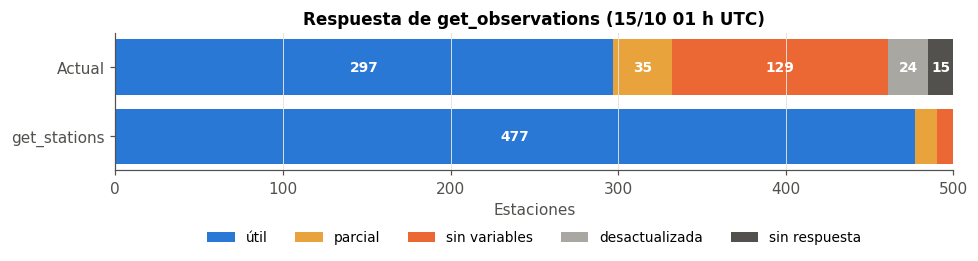

In [10]:
COLORES_RESULTADO = {'útil': AZUL, 'parcial': '#e8a33d', 'sin variables': NARANJA,
                     'desactualizada': '#a9a7a1', 'sin respuesta': GRIS_TEXTO}

fig, ax = plt.subplots(figsize=(9, 2.8))
izquierda = np.zeros(len(conteo.columns))
for cat in CATEGORIAS:
    valores = conteo.loc[cat].values
    ax.barh(conteo.columns, valores, left=izquierda, color=COLORES_RESULTADO[cat], label=cat)
    for y, (x0, v) in enumerate(zip(izquierda, valores)):
        if v >= 15:
            ax.text(x0 + v / 2, y, str(v), ha='center', va='center', color='white', fontsize=9, fontweight='bold')
    izquierda += valores
ax.invert_yaxis()
ax.set_xlabel('Estaciones')
ax.set_title(f'Respuesta de get_observations ({hora_corrida:%d/%m %H} h UTC)')
ax.legend(ncol=5, loc='upper center', bbox_to_anchor=(0.5, -0.35), frameon=False, fontsize=9)
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

### Cobertura por variable

Porcentaje de estaciones cuya respuesta trae cada variable (sobre las que respondieron).

In [11]:
cobertura_variables = pd.DataFrame({
    n: (r.loc[r['resultado'] != 'sin respuesta', VARIABLES_UTILES + VARIABLES_INFORMATIVAS]
        .astype(float).mean() * 100).round(1)
    for n, r in resultados.items()
})
cobertura_variables

,Actual,get_stations
temperature,70.7,97.4
dewpoint,65.8,96.8
relativeHumidity,65.8,96.6
windSpeed,69.5,96.6
windDirection,68.7,96.2
heatIndex,50.7,33.6


### Resultado en el mapa

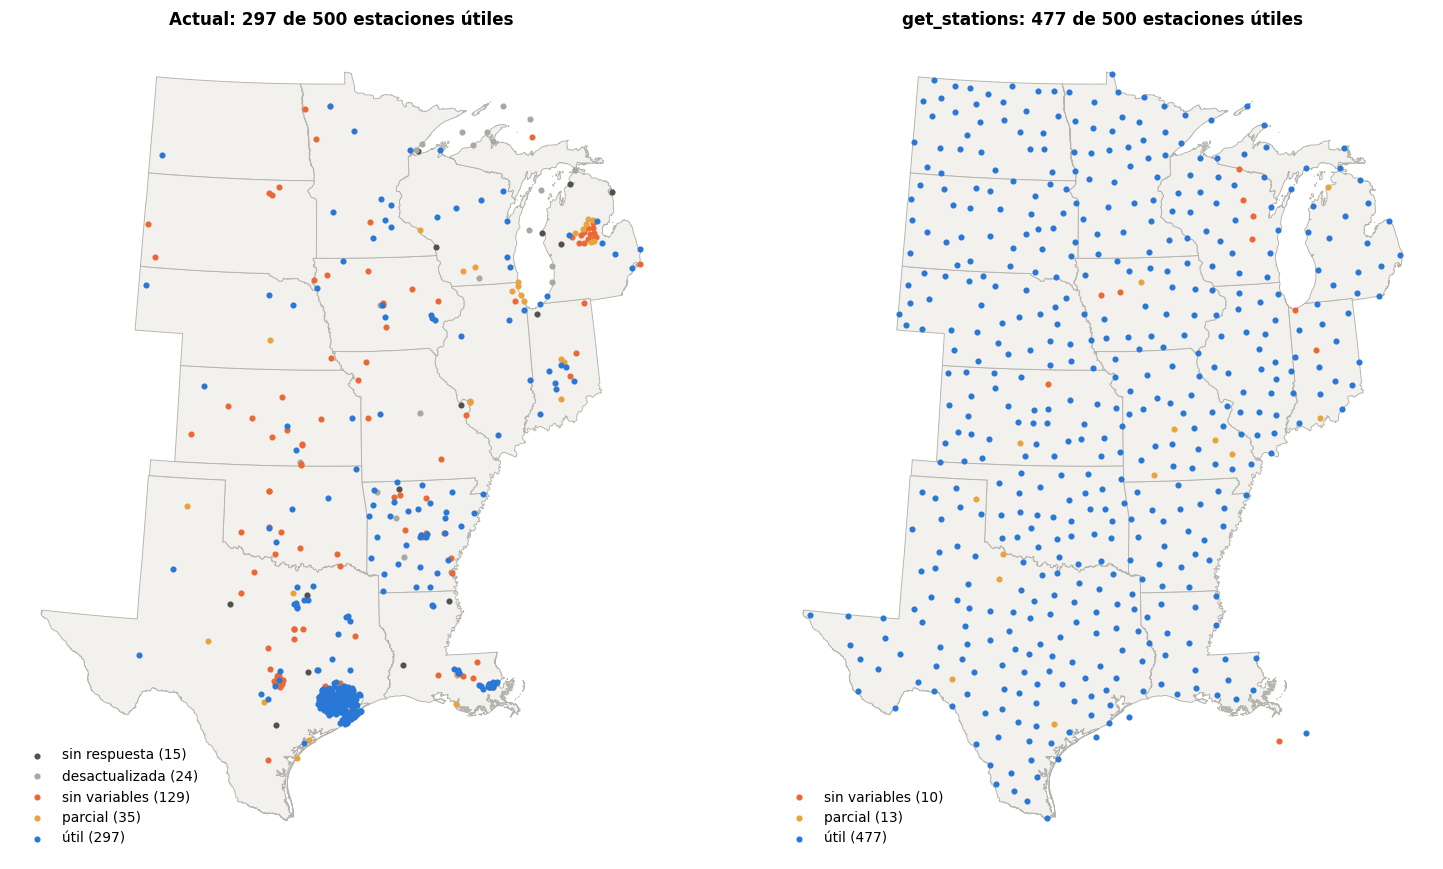

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 8))
for ax, (nombre, r) in zip(axes, resultados.items()):
    estados.plot(ax=ax, color='#f2f1ee', edgecolor='#b5b3ad', linewidth=0.6)
    gdf = a_gdf(r)
    for cat in CATEGORIAS[::-1]:  # las útiles quedan arriba
        puntos = gdf[gdf['resultado'] == cat]
        if len(puntos):
            puntos.plot(ax=ax, markersize=9, color=COLORES_RESULTADO[cat], label=f'{cat} ({len(puntos)})')
    utiles = (r['resultado'] == 'útil').sum()
    ax.set_title(f'{nombre}: {utiles} de {len(r)} estaciones útiles')
    ax.legend(loc='lower left', frameon=False, fontsize=9)
    ax.set_axis_off()
plt.tight_layout()
plt.show()

### Estaciones de la selección nueva que no devolvieron datos útiles

In [13]:
columnas = ['id', 'nombre', 'estado', 'provider', 'subProvider', 'cobertura_horaria', 'resultado', 'edad_h']
no_utiles = resultados['get_stations'].loc[resultados['get_stations']['resultado'] != 'útil', columnas + VARIABLES_UTILES]
print(f'{len(no_utiles)} de {len(seleccion)} estaciones')
no_utiles.round({'edad_h': 1}).sort_values(['resultado', 'id'])

23 de 500 estaciones


,id,nombre,estado,provider,subProvider,cobertura_horaria,resultado,edad_h,temperature,dewpoint,relativeHumidity,windSpeed
17,CBFM7,COUNCIL BLUFF,MO,RAWS,,0.83,parcial,1.3,False,False,False,True
93,KAIZ,"Kaiser Lake Ozark, Lee C Fine Memorial Airport",MO,ASOS-HFM,,0.83,parcial,0.3,True,False,False,True
138,KCAV,Clarion,IA,OTHER-MTR,,0.83,parcial,0.4,True,False,False,True
156,KCVX,"Charlevoix, Charlevoix Municipal Airport",MI,OTHER-MTR,,0.83,parcial,0.7,True,True,True,False
204,KF05,"Vernon, Wilbarger County Airport",TX,OTHER-MTR,,0.83,parcial,0.4,True,True,True,False
218,KFWB,Branson West Muni - Emerson Field,MO,OTHER-MTR,,1.00,parcial,0.4,True,True,True,False
243,KHHF,"Canadian, Hemphill County Airport",TX,OTHER-MTR,,1.00,parcial,0.4,True,True,True,False
369,KPTT,Pratt Municipal,KS,OTHER-MTR,,0.83,parcial,0.7,True,True,True,False
451,MCBT2,MILLER CREEK,TX,RAWS,,0.83,parcial,0.6,False,True,False,False
463,PMRM7,PIEDMONT,MO,RAWS,,0.83,parcial,1.1,True,False,False,True


**Cómo leer esta tabla.** Varias de estas estaciones pasaron la verificación con todas las horas completas y, aun así,
acá aparecen como *sin variables* o *parcial*. No es una falla de la estación: api.weather.gov publica cada
observación apenas llega, con el METAR crudo en `rawMessage` pero los valores todavía en `null`, y los completa unos
minutos después. Si `/observations/latest` se consulta en ese intervalo, devuelve el registro vacío. Por eso
`get_stations` verifica la última observación de cada hora ya cerrada, que es la que quedó completa.

Este efecto le pasa por igual a cualquier lista de estaciones y depende del minuto en que corre `get_observations`.
Para reducirlo habría que cambiar `get_observations`: por ejemplo, pedir `/observations?limit=3` y quedarse con la
más reciente que esté completa, o programarla unos minutos después de la hora en punto.

In [14]:
utiles = {n: (r['resultado'] == 'útil').sum() for n, r in resultados.items()}
print(f"Estaciones con datos útiles a las {hora_corrida:%H} h UTC del {hora_corrida:%d/%m}:")
for nombre, n in utiles.items():
    print(f'  {nombre:13s} {n} de {len(resultados[nombre])} ({n / len(resultados[nombre]):.0%})')
print(f"  Diferencia: {utiles['get_stations'] - utiles['Actual']:+d} estaciones útiles")

Estaciones con datos útiles a las 01 h UTC del 15/10:
  Actual        297 de 500 (59%)
  get_stations  477 de 500 (95%)
  Diferencia: +180 estaciones útiles
